# 🏦🌊 *You shall know a word by the **corpus** it keeps*
## A hands-on tour of lexical and vector semantics
### NLP / PLN · MEIC & MEIM · ISEL · Module 4: Semantics

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matpato/SemShift/blob/main/notebooks/SemShift_tutorial.ipynb)

**The idea.** Firth (1957) said *"you shall know a word by the company it keeps"*. We take this literally.
We let a computer read **two very different worlds** and learn word meanings **from scratch**:

| | 🏦 **Reuters-21578** | 📜 **Project Gutenberg** (NLTK selection) |
|---|---|---|
| What | 10,788 financial news stories | 18 classic books: Austen, Shakespeare, the King James Bible, Melville, Milton, Carroll… |
| When | 1987 | 1611–1911 |
| Size | ≈ 1.3 M words | ≈ 2.1 M words |

Then we ask the same question to both: ***what does `bank` mean?***
The answer depends on the world: *central, banks, governor* in one, *brink, hill, hedge* in the other.
Along the way we touch **every learning outcome** of the module:

| # | Learning outcome | Where |
|---|---|---|
| LO1 | Lexical semantics (synonymy, polysemy, hyponymy, meronymy) and WordNet | [§1](#s1) |
| LO2 | The distributional hypothesis | [§2](#s2) |
| LO3 | Sparse (co-occurrence, TF-IDF, PPMI) and dense (embedding) vectors | [§3](#s3), [§4](#s4) |
| LO4 | Cosine similarity for words and documents | [§3](#s3), [§4](#s4), [§5](#s5) |
| LO5 | Word sense disambiguation vs. entity linking | [§6](#s6), [§7](#s7) |
| LO6 | How word2vec/GloVe are trained, and their limitations (polysemy, bias) | [§4](#s4), [§8](#s8) |
| 🇵🇹 | Bonus: Machado de Assis (19th c.) vs. *Folha de S. Paulo* (1994) | [§9](#s9) |

**Runtime.** Everything runs on a free Colab CPU in **≈ 8–10 minutes** in total (the largest steps are the
128 MB GloVe download and training 2 word2vec models, ≈ 1 min each). No GPU is needed.

> 🔮 **Golden rule: predict before you run.** Every cell marked 🔮 asks you to write a prediction first.
> The surprises are where the learning is.

<a id="s0"></a>
## 0. Setup

In [1]:
# On Colab, gensim is not pre-installed (≈ 30 s). Locally: pip install -r requirements.txt
import importlib.util, subprocess, sys
if importlib.util.find_spec("gensim") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gensim>=4.4"], check=True)

In [2]:
import re, json, time, random, collections, warnings
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import nltk
warnings.filterwarnings("ignore")

for pkg in ["reuters", "gutenberg", "wordnet", "omw-1.4", "omw-2.0", "stopwords", "punkt", "machado", "mac_morpho"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import reuters, gutenberg, wordnet as wn, stopwords
STOP = set(stopwords.words("english"))

# One colour per "world", used in every chart
C_R, C_G, C_W = "#2a78d6", "#eb6834", "#1baf7a"   # Reuters, Gutenberg, GloVe (Wikipedia)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#9b9a95", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9})
T0 = time.time()
print("ready")

ready


In [3]:
def clean(sents):
    """Lower-case, keep alphabetic tokens, drop very short sentences."""
    out = []
    for s in sents:
        t = [w.lower() for w in s if re.fullmatch(r"[A-Za-z][A-Za-z'-]*", w)]
        if len(t) > 2:
            out.append(t)
    return out

t = time.time()
SENTS = {"reuters": clean(reuters.sents()), "gutenberg": clean(gutenberg.sents())}
for name, S in SENTS.items():
    n_tok = sum(map(len, S)); vocab = len({w for s in S for w in s})
    print(f"{name:10s} {len(S):7,d} sentences  {n_tok:10,d} tokens  {vocab:7,d} word types")
print(f"({time.time()-t:.0f} s)")

reuters     54,225 sentences   1,326,285 tokens   29,163 word types
gutenberg   90,532 sentences   2,125,113 tokens   41,248 word types
(17 s)


<a id="s1"></a>
## 1. Lexical semantics and WordNet (LO1)

Before learning anything from data, let us ask a **hand-built** resource. WordNet groups lemmas into
**synsets** (sets of synonyms = one concept) linked by relations: hypernymy (IS-A), meronymy (PART-OF), antonymy…

🔮 **Predict:** how many *noun* senses does WordNet list for `bank`? Which one comes first?

In [4]:
for i, s in enumerate(wn.synsets("bank", pos="n"), 1):
    print(f"{i:2d}. {s.name():40s} {s.definition()[:70]}")

 1. bank.n.01                                sloping land (especially the slope beside a body of water)
 2. depository_financial_institution.n.01    a financial institution that accepts deposits and channels the money i
 3. bank.n.03                                a long ridge or pile
 4. bank.n.04                                an arrangement of similar objects in a row or in tiers
 5. bank.n.05                                a supply or stock held in reserve for future use (especially in emerge
 6. bank.n.06                                the funds held by a gambling house or the dealer in some gambling game
 7. bank.n.07                                a slope in the turn of a road or track; the outside is higher than the
 8. savings_bank.n.02                        a container (usually with a slot in the top) for keeping money at home
 9. bank.n.09                                a building in which the business of banking transacted
10. bank.n.10                                a fli

Two families of senses: **homonymy** (unrelated meanings that share a form: the *river side* vs. the *financial institution*)
and **polysemy** (related senses: the institution `depository_financial_institution.n.01` vs. the building `bank.n.09`).
Note that sense 1 is the **river bank**: WordNet orders senses by their frequency in SemCor (general American English
of the 1960s). Remember this; it will hurt us in §6.

Now the **relations**: synonymy (lemmas of a synset), hypernymy (the path to the root), hyponymy (more specific kinds),
meronymy (parts) and antonymy.

In [5]:
fin  = wn.synset("depository_financial_institution.n.01")
side = wn.synset("bank.n.01")

print("SYNONYMS of", fin.name(), "->", fin.lemma_names())
print("\nHYPERNYM path (IS-A) of the financial sense:")
print("  " + " → ".join(s.lemma_names()[0] for s in fin.hypernym_paths()[0]))
print("HYPERNYM path of the river-side sense:")
print("  " + " → ".join(s.lemma_names()[0] for s in side.hypernym_paths()[0]))
print("\nHYPONYMS (kinds of financial bank):", sorted(l for h in fin.hyponyms() for l in h.lemma_names()[:1]))
print("MEMBER HOLONYMS of a bank (what it is part of):", [h.name() for h in fin.member_holonyms()])
print("PART MERONYMS of a building:", [m.lemma_names()[0] for m in wn.synset("building.n.01").part_meronyms()][:8])
print("ANTONYM of 'interesting':", wn.synset("interesting.a.01").lemmas()[0].antonyms())
print("\nLowest common hypernym (river bank, financial bank):", side.lowest_common_hypernyms(fin))
print(f"Path similarity: {side.path_similarity(fin):.3f}   Wu-Palmer: {side.wup_similarity(fin):.3f}")

SYNONYMS of depository_financial_institution.n.01 -> ['depository_financial_institution', 'bank', 'banking_concern', 'banking_company']

HYPERNYM path (IS-A) of the financial sense:
  entity → abstraction → group → social_group → organization → institution → financial_institution → depository_financial_institution
HYPERNYM path of the river-side sense:
  entity → physical_entity → object → geological_formation → slope → bank

HYPONYMS (kinds of financial bank): ['Federal_Reserve_Bank', 'Home_Loan_Bank', 'acquirer', 'agent_bank', 'commercial_bank', 'credit_union', 'lead_bank', 'member_bank', 'merchant_bank', 'state_bank', 'thrift_institution']
MEMBER HOLONYMS of a bank (what it is part of): ['banking_industry.n.01']
PART MERONYMS of a building: ['shaft', 'corner', 'elevator', 'annex', 'anteroom', 'upstairs', 'crawlspace', 'roof']
ANTONYM of 'interesting': [Lemma('uninteresting.a.01.uninteresting')]

Lowest common hypernym (river bank, financial bank): [Synset('entity.n.01')]
Path simila

The two `bank`s only meet at **`entity.n.01`**, the root of the whole hierarchy: they are as unrelated as two nouns can be.
Homonymy is also **language specific**: Portuguese splits the senses differently (*banco* = bank **and** bench; the river side is *margem*).

In [6]:
for s in ["bank.n.01", "depository_financial_institution.n.01", "bench.n.01"]:
    print(f"{s:40s} PT: {wn.synset(s).lemma_names('por')}")

bank.n.01                                PT: ['costa', 'margem']
depository_financial_institution.n.01    PT: ['banco', 'Bancos']
bench.n.01                               PT: ['banco', 'Banco']


How ambiguous are the words we will meet later? Count their WordNet senses (all parts of speech):

In [7]:
WORDS = ["bank", "interest", "stock", "share", "capital", "light", "court", "house", "board", "mine", "tender", "fair"]
counts = {w: len(wn.synsets(w)) for w in WORDS}
print("  ".join(f"{w}:{n}" for w, n in sorted(counts.items(), key=lambda x: -x[1])))

light:47  stock:27  bank:18  tender:18  fair:17  court:14  house:14  board:13  capital:11  interest:10  share:10  mine:4


💬 **Discuss.** WordNet is precise and interpretable, but it was **built by hand**: it does not know that in
1987 news *tender* almost always means a *tender offer* for shares, or that *bank* in finance news is never a river side.
Can we learn meaning **automatically from text**? → the distributional hypothesis.

<a id="s2"></a>
## 2. The distributional hypothesis (LO2)

> *"If A and B have almost identical environments we say that they are synonyms."* (Harris, 1954)

Before any maths, **look at the company `bank` keeps** in each world (a *keyword-in-context* view):

In [8]:
def kwic(sents, word, n=6, width=6, seed=1):
    random.seed(seed)
    hits = [(s, i) for s in sents for i, w in enumerate(s) if w == word]
    for s, i in random.sample(hits, n):
        left, right = " ".join(s[max(0, i-width):i]), " ".join(s[i+1:i+1+width])
        print(f"{left:>45s}  [{word}]  {right}")
    return len(hits)

for name in SENTS:
    print(f"\n=== {name.upper()} ===")
    n = kwic(SENTS[name], "bank")
    print(f"({n} occurrences)")


=== REUTERS ===
                                          the  [bank]  report said indonesia s rice production
                                               [bank]  of b c
       in saudi arabia lt national commercial  [bank]  ncb won a licence in november
     chief pledges support to indonesia world  [bank]  president barber conable pledged the bank
             credits to concerns in which the  [bank]  itself has a stake and to
             savings bank said it and neworld  [bank]  for savings have agreed to merge
(3654 occurrences)

=== GUTENBERG ===
                      one on this side of the  [bank]  of the river and the other
                  just as he was climbing the  [bank]  into the old man s garden
                 from aroer which is upon the  [bank]  of the river arnon and from
                                 there on the  [bank]  beside the little pool were the
                 i had returned behold at the  [bank]  of the river were very many
            by one th

🔮 **Predict:** which words will be the most frequent **neighbours** (±5 words, stopwords removed) of `bank` in each corpus?

In [9]:
def context_counts(sents, word, win=5):
    c = collections.Counter()
    for s in sents:
        for i, w in enumerate(s):
            if w == word:
                c.update(x for x in s[max(0, i-win):i] + s[i+1:i+1+win] if x not in STOP and x != word)
    return c

for name in SENTS:
    top = context_counts(SENTS[name], "bank").most_common(12)
    print(f"{name:10s}", ", ".join(f"{w}({c})" for w, c in top))

reuters    said(964), central(581), lt(343), mln(317), japan(242), england(225), pct(219), national(199), billion(168), stg(163), dlrs(148), rate(148)


gutenberg  river(16), upon(8), little(8), side(5), green(5), steep(4), aroer(4), arnon(4), head(4), ran(3), hedge(3), behold(3)


Even raw counts already "know" the meaning: *central, england, rate, billion* vs. *river, side, green, steep*.
**The whole rest of this notebook is about turning this intuition into vectors.**

<a id="s3"></a>
## 3. Sparse vectors: TF-IDF documents and PPMI words (LO3, LO4)

### 3.1 Term–document matrix + TF-IDF: can the computer group books by author?
Each of the 18 Gutenberg books becomes a **column vector** of TF-IDF weights over the vocabulary
(the bag-of-words of Module 3). We compare books with **cosine similarity**:
$\cos(\mathbf{v},\mathbf{w}) = \frac{\mathbf{v}\cdot\mathbf{w}}{\|\mathbf{v}\|\,\|\mathbf{w}\|}$.

🔮 **Predict:** which book will be most similar to *Hamlet*? To the *Bible*? To *Moby Dick*?

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

books = gutenberg.fileids()
tfidf = TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True)   # tf = 1 + log(count)
X = tfidf.fit_transform(gutenberg.raw(f) for f in books)                   # 18 x |V| sparse matrix
print(f"term-document matrix: {X.shape[0]} books x {X.shape[1]:,} terms, {100*X.nnz/np.prod(X.shape):.1f}% non-zero")

S = cosine_similarity(X)
short = [b.replace(".txt", "") for b in books]
for i, b in enumerate(short):
    j = np.argsort(-S[i])[1]
    print(f"{b:24s} → {short[j]:24s} cos = {S[i, j]:.2f}")

term-document matrix: 18 books x 19,399 terms, 27.2% non-zero
austen-emma              → austen-sense             cos = 0.72
austen-persuasion        → austen-emma              cos = 0.70
austen-sense             → austen-emma              cos = 0.72
bible-kjv                → milton-paradise          cos = 0.50
blake-poems              → milton-paradise          cos = 0.31
bryant-stories           → edgeworth-parents        cos = 0.41
burgess-busterbrown      → carroll-alice            cos = 0.37
carroll-alice            → bryant-stories           cos = 0.40
chesterton-ball          → chesterton-thursday      cos = 0.61
chesterton-brown         → chesterton-ball          cos = 0.59
chesterton-thursday      → chesterton-ball          cos = 0.61
edgeworth-parents        → austen-emma              cos = 0.55
melville-moby_dick       → whitman-leaves           cos = 0.58
milton-paradise          → bible-kjv                cos = 0.50
shakespeare-caesar       → shakespeare-hamlet       cos 

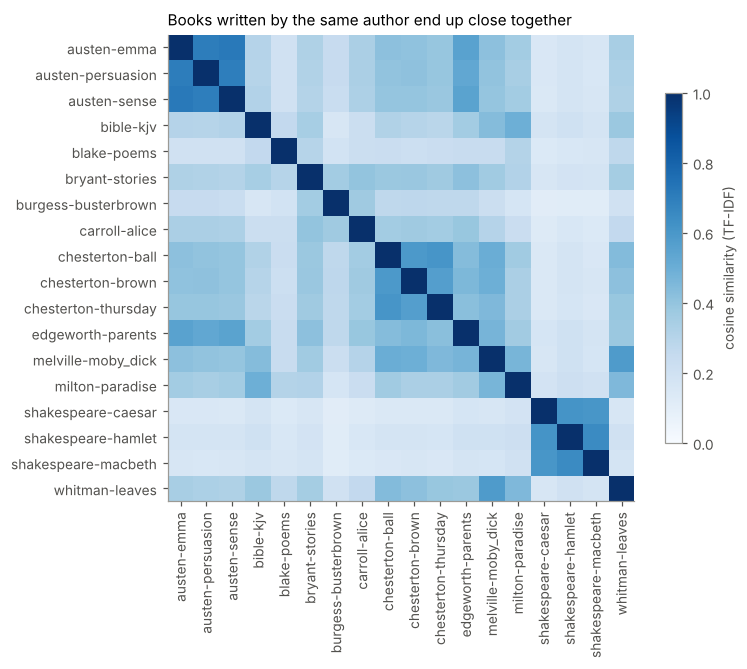

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(short))); ax.set_xticklabels(short, rotation=90)
ax.set_yticks(range(len(short))); ax.set_yticklabels(short)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="cosine similarity (TF-IDF)")
ax.set_title("Books written by the same author end up close together", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

The three Austen novels, the three Shakespeare plays and the three Chesterton books form **blocks**, and the Bible is
closest to Milton's *Paradise Lost*. Nobody told the model who wrote what: **documents with similar words are similar**.

The same matrix read **by rows** gives *word* vectors (a word = the books it appears in). Which words are distributed like `whale`?

In [12]:
vocab_index = tfidf.vocabulary_
Xt = X.T.tocsr()                      # |V| x 18: one row per word
inv = np.array(tfidf.get_feature_names_out())
def doc_neighbours(word, k=8):
    v = Xt[vocab_index[word]]
    sims = cosine_similarity(v, Xt).ravel(); sims[vocab_index[word]] = -1
    return list(inv[np.argsort(-sims)[:k]])
for w in ["whale", "lord", "rabbit", "sister"]:
    print(f"{w:8s}", doc_neighbours(w))

whale    ['mast', 'gull', 'tub', 'longingly', 'seam', 'hammers', 'greenness', 'lance']
lord     ['send', 'nay', 'blood', 'grace', 'faith', 'honest', 'mirth', 'touch']
rabbit   ['sh', 'grin', 'twinkling', 'doesn', 'wasn', 'swam', 'scrambling', 'twinkle']
sister   ['bringing', 'sooner', 'wretched', 'person', 'considered', 'letter', 'settled', 'immediately']


Reasonable, but coarse: with only 18 "dimensions", words are similar just because they live in the **same book**.
For word meaning we need a **smaller context**.

### 3.2 Word–context matrix + PPMI
Count how often each word appears within **±2 words** of each context word (10,000 most frequent words → a
10,000 × 10,000 matrix), then re-weight with **positive pointwise mutual information**:
$\mathrm{PPMI}(w,c) = \max\left(\log_2 \frac{P(w,c)}{P(w)\,P_{\alpha}(c)},\ 0\right)$, with $\alpha = 0.75$.

In [13]:
def cooc_matrix(sents, V=10_000, win=2):
    freq = collections.Counter(w for s in sents for w in s)
    vocab = [w for w, _ in freq.most_common(V)]
    ix = {w: i for i, w in enumerate(vocab)}
    rows, cols = [], []
    for s in sents:
        ids = [ix.get(w, -1) for w in s]
        for i, a in enumerate(ids):
            if a < 0: continue
            for j in range(max(0, i-win), min(len(ids), i+win+1)):
                if j != i and ids[j] >= 0:
                    rows.append(a); cols.append(ids[j])
    C = sp.coo_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(V, V)).tocsr()
    return vocab, ix, C

def ppmi(C, alpha=0.75):
    total = C.sum()
    p_w = np.asarray(C.sum(1)).ravel() / total
    c_cnt = np.asarray(C.sum(0)).ravel() ** alpha
    p_c = c_cnt / c_cnt.sum()
    M = C.tocoo()
    pmi = np.log2((M.data / total) / (p_w[M.row] * p_c[M.col]))
    keep = pmi > 0
    return sp.csr_matrix((pmi[keep], (M.row[keep], M.col[keep])), shape=C.shape)

t = time.time()
SPARSE = {}
for name, S_ in SENTS.items():
    vocab, ix, C = cooc_matrix(S_)
    SPARSE[name] = dict(vocab=vocab, ix=ix, C=C, P=ppmi(C))
    print(f"{name:10s} {C.shape[0]:,} x {C.shape[1]:,}  non-zero: {100*C.nnz/np.prod(C.shape):.2f}%")
print(f"({time.time()-t:.0f} s)")

reuters    10,000 x 10,000  non-zero: 1.00%


gutenberg  10,000 x 10,000  non-zero: 1.38%
(5 s)


More than **98 % of the cells are zero**: these are *sparse* vectors.
Let us compute one cosine **by hand** on three real dimensions before trusting the library:

In [14]:
D = SPARSE["reuters"]; ctx = ["central", "england", "rates"]
for w in ["bank", "banks", "river"]:
    if w in D["ix"]:
        print(f"{w:6s}", {c: int(D["C"][D["ix"][w], D["ix"][c]]) for c in ctx})
b  = np.array([D["C"][D["ix"]["bank"],  D["ix"][c]] for c in ctx])
bs = np.array([D["C"][D["ix"]["banks"], D["ix"][c]] for c in ctx])
print(f"\ncos(bank, banks) on these 3 dimensions = {b @ bs / (np.linalg.norm(b) * np.linalg.norm(bs)):.3f}")

bank   {'central': 549, 'england': 216, 'rates': 17}
banks  {'central': 96, 'england': 0, 'rates': 10}
river  {'central': 0, 'england': 0, 'rates': 0}

cos(bank, banks) on these 3 dimensions = 0.928


🔮 **Predict:** with **raw counts**, will the nearest neighbours of `bank` be good? And with **PPMI**?

In [15]:
from sklearn.preprocessing import normalize

def sparse_neighbours(name, word, weight="P", k=7):
    D = SPARSE[name]; M = normalize(D[weight])          # unit rows → dot product = cosine
    i = D["ix"][word]
    sims = (M @ M[i].T).toarray().ravel(); sims[i] = -1
    return [D["vocab"][j] for j in np.argsort(-sims)[:k]]

for w in ["bank", "interest", "light", "house"]:
    for name in SENTS:
        print(f"{w:9s} {name:10s} counts: {', '.join(sparse_neighbours(name, w, 'C'))}")
        print(f"{'':9s} {'':10s} PPMI:   {', '.join(sparse_neighbours(name, w, 'P'))}")
    print()

bank      reuters    counts: acquisition, strength, success, most, size, significance, value
                     PPMI:   central, banks, savings, national, bancorp, governor, banking
bank      gutenberg  counts: wall, threshold, road, top, floor, sea, edge
                     PPMI:   brink, surf, hill, grove, balcony, hedge, docks

interest  reuters    counts: base, rise, drop, february, growth, increase, january
                     PPMI:   rates, rate, visa, prices, substantial, discount, debt
interest  gutenberg  counts: delight, pleasure, satisfaction, power, company, ears, distress
                     PPMI:   curiosity, ecstasy, partiality, satisfaction, importance, development, confidence

light     reuters    counts: parts, interests, land, operation, context, volume, wake
                     PPMI:   sweet, edmonton, grade, crude, bonny, swann, benchmark
light     gutenberg  counts: most, plain, city, water, spirit, truth, smoke
                     PPMI:   sun, shine, sky, 

                     PPMI:   senate, white, committee, subcommittee, speaker, appropriations, hearing


house     gutenberg  counts: land, family, sanctuary, king, tabernacle, valley, prince


                     PPMI:   sons, court, son, building, cottage, temple, altar



💬 **Discuss.** Raw counts are dominated by **frequent context words** (*the, of, in*), so `bank` looks like
*acquisition, strength, size*. PPMI asks "do these co-occur **more than chance**?" and the meaning appears:
`light` = *sweet, crude, grade* in Reuters (light sweet crude oil!) and *sun, shine, sky, moon* in Gutenberg.

<a id="s4"></a>
## 4. Dense vectors: training word2vec on each world (LO3, LO6)

**Skip-gram with negative sampling (SGNS)**: for each (target, context) pair inside a window, train a logistic
regression to tell it apart from *k* random "negative" words, $P(+\mid w,c) = \sigma(\mathbf{c}\cdot\mathbf{w})$.
The learned weights **are** the embeddings: 100 real numbers per word instead of 10,000 mostly-zero counts.

| hyper-parameter | value | meaning |
|---|---|---|
| `sg=1` | skip-gram | predict the context from the word (CBOW is the reverse) |
| `vector_size` | 100 | dimensions *d* |
| `window` | 5 | ±5 words of context |
| `negative` | 5 | *k* negative samples per positive pair, drawn from $P_{0.75}$ |
| `min_count` | 5 | ignore rarer words |
| `epochs` | 10 | passes over the corpus |

🔮 **Predict:** how long will training take on ≈ 1–2 M words with 2 CPU cores?

In [16]:
from gensim.models import Word2Vec

W2V = {}
for name, S_ in SENTS.items():
    t = time.time()
    m = Word2Vec(S_, vector_size=100, window=5, sg=1, negative=5, min_count=5,
                 epochs=10, workers=2, seed=42)
    W2V[name] = m.wv
    print(f"{name:10s} trained in {time.time()-t:4.0f} s   vocabulary: {len(m.wv):,} words x {m.wv.vector_size} dims")

reuters    trained in   33 s   vocabulary: 10,424 words x 100 dims


gutenberg  trained in   51 s   vocabulary: 15,366 words x 100 dims


We also load a **third world**, pre-trained **GloVe** (Wikipedia + Gigaword news, 6 billion tokens, 400k words).
GloVe is trained differently: it fits $\mathbf{w}_i\cdot\tilde{\mathbf{w}}_j + b_i + \tilde b_j \approx \log X_{ij}$ on the
**global** co-occurrence counts. (128 MB download, ≈ 1–2 min the first time.)

In [17]:
import gensim.downloader as api
t = time.time()
GLOVE = api.load("glove-wiki-gigaword-100")
print(f"GloVe: {len(GLOVE):,} words x {GLOVE.vector_size} dims ({time.time()-t:.0f} s)")

GloVe: 400,000 words x 100 dims (30 s)


### 4.1 🎯 The main result: the same word in three worlds
🔮 **Predict** the neighbours of each word in each world **before** running. (Hint: think *Bible*, *Jane Austen*, *Wall Street*.)

In [18]:
from IPython.display import HTML, display

def nn(kv, w, k=6):
    return ", ".join(x for x, _ in kv.most_similar(w, topn=k)) if w in kv else "— (not in vocabulary)"

def three_worlds(words):
    rows = "".join(
        f"<tr><td><b>{w}</b></td><td>{nn(W2V['reuters'], w)}</td><td>{nn(W2V['gutenberg'], w)}</td><td>{nn(GLOVE, w)}</td></tr>"
        for w in words)
    display(HTML(f'''<table style="font-size:12px">
      <tr><th>word</th><th style="color:{C_R}">🏦 Reuters 1987</th><th style="color:{C_G}">📜 Gutenberg</th>
      <th style="color:{C_W}">🌍 GloVe (Wikipedia)</th></tr>{rows}</table>'''))

three_worlds(["bank", "interest", "stock", "light", "court", "house", "board", "mine", "tender", "sound", "fair", "spirit"])

word,🏦 Reuters 1987,📜 Gutenberg,🌍 GloVe (Wikipedia)
bank,"banks, satoshi, england, central, sumita, westminster","pool, cafe, meadow, footpath, lawn, slope","banks, banking, credit, investment, financial, securities"
interest,"adjusts, spectrum, term, moratorium, visa, overdraft","negative, importance, uneasiness, candour, gallantry, civility","rates, raise, value, concern, borrowing, rate"
stock,"common, shares, berkey, preferred, exchangeable, datacard","included, scanty, tidy, slated, dimensions, turtledoves","shares, stocks, market, exchange, trading, investors"
light,"sweet, bonny, crudes, netbacks, naphtha, slope","shineth, darkness, brightness, shine, stars, noonday","dark, bright, lights, air, blue, visible"
court,"appeals, injunction, chancery, bankruptcy, appeal, justice","porch, inner, chambers, temple, entry, palace","judge, appeals, supreme, courts, trial, case"
house,"subcommittee, senate, white, appropriations, speaker, testifying","chamber, tabernacle, tent, millo, palace, shiloh","office, senate, room, houses, capitol, building"
board,"directors, unanimously, nominees, supervisory, acceptance, slate","pequod, trading, tenons, ship, bushel, schooner","commission, committee, directors, executive, council, panel"
mine,"gold, leaching, copper, geodome, chibougamau, leach","thine, my, evildoers, hatest, wrongfully, deepe","coal, mines, miners, mining, accident, explosion"
tender,"offer, tenders, tendering, loving, tendered, offers","giver, vernal, glow, wholesome, yielding, youthful","sweet, cooked, tenders, crisp, fresh, flavorful"
sound,"finances, prerequisite, leiner, grave, behavior, cooling","cornet, drums, trumpet, flute, mirth, sonorous","sounds, music, acoustic, voice, noise, guitar"


💬 **Discuss.**
* `bank`: *central, england, banks* vs. *pool, meadow, footpath*: **homonymy, resolved by the corpus**.
* `light`: *sweet, crudes, naphtha* (oil grades) vs. *shineth, stars, darkness*.
* `mine`: *copper, gold, ounces* vs. *thine, my*: a **different part of speech** (noun vs. pronoun)!
* `house`: *senate, subcommittee* (the US House) vs. *chamber, tabernacle, palace*.
* GloVe, trained on a **mixture** of everything, mostly follows the **most frequent** sense.

Each model has learned **one vector per word**, and which meaning that vector holds is decided by the corpus.

> ℹ️ Your neighbours may differ slightly from the ones described here: word2vec training with several threads is not
> fully deterministic. The *meanings* are stable; the exact lists are not (PPMI, in §3, is deterministic).

### 4.2 A picture of meaning
Project the vectors of `bank` and its neighbours onto 2 dimensions (PCA). Each corpus has its own space,
so we draw two panels.

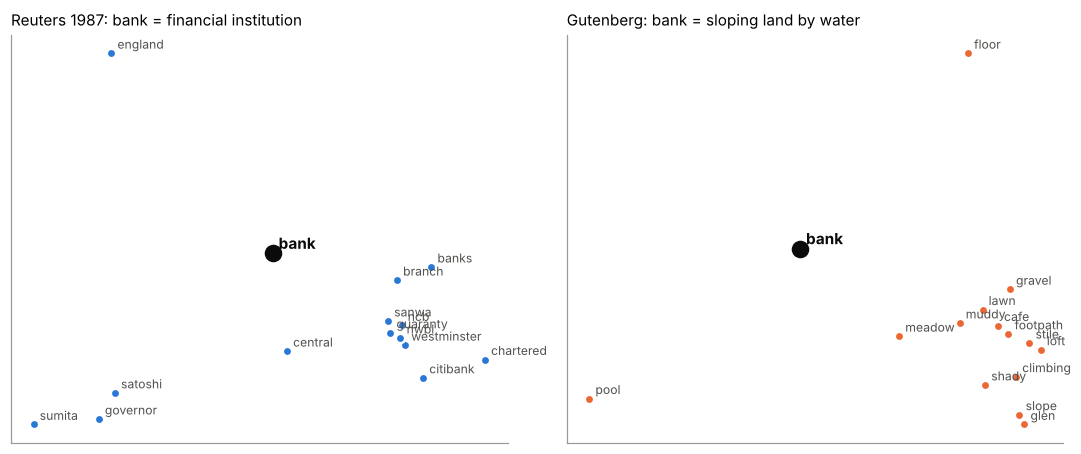

In [19]:
from sklearn.decomposition import PCA

def plot_space(ax, kv, center, color, title, k=14):
    words = [center] + [w for w, _ in kv.most_similar(center, topn=k)]
    xy = PCA(n_components=2, random_state=0).fit_transform(np.array([kv[w] for w in words]))
    ax.scatter(xy[1:, 0], xy[1:, 1], s=36, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter(xy[0, 0], xy[0, 1], s=110, color="#0b0b0b", zorder=4)
    for (x, y), w in zip(xy, words):
        ax.annotate(w, (x, y), xytext=(4, 3), textcoords="offset points",
                    fontsize=10 if w == center else 8, color="#0b0b0b" if w == center else "#52514e",
                    fontweight="bold" if w == center else "normal")
    ax.set_title(title, loc="left", fontsize=10); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_space(axes[0], W2V["reuters"],   "bank", C_R, "Reuters 1987: bank = financial institution")
plot_space(axes[1], W2V["gutenberg"], "bank", C_G, "Gutenberg: bank = sloping land by water")
plt.tight_layout(); plt.show()

### 4.3 Analogies (the parallelogram model) inside each world
$\vec{b} - \vec{a} + \vec{a'} \approx \vec{b'}$. With 1–2 M words analogies are fragile, so compare with GloVe.

In [20]:
def analogy(kv, a, b, a2, k=3):
    try:
        return ", ".join(x for x, _ in kv.most_similar(positive=[b, a2], negative=[a], topn=k))
    except KeyError as e:
        return f"— ({e.args[0].split()[1]} unknown)"

for a, b, a2 in [("man", "king", "woman"), ("oil", "crude", "gold"), ("france", "paris", "japan"), ("he", "his", "she")]:
    print(f"{a}:{b} :: {a2}:?   R → {analogy(W2V['reuters'], a, b, a2):30s} G → {analogy(W2V['gutenberg'], a, b, a2):30s} GloVe → {analogy(GLOVE, a, b, a2)}")

man:king :: woman:?   R → — ('woman' unknown)            G → daughter, solomon, vashti      GloVe → queen, monarch, throne
oil:crude :: gold:?   R → silver, ounces, ounce          G → borderland, plaited, patches   GloVe → silver, bronze, platinum
france:paris :: japan:?   R → louvre, accord, spirit         G → sunda, icebergs, lanterns      GloVe → tokyo, osaka, japanese
he:his :: she:?   R → loewy, penner, jeffrey         G → her, fondness, herself         GloVe → her, mother, wife


💬 *woman* is not even in the Reuters vocabulary (fewer than 5 occurrences in 1.3 M words!); in our run the Bible answered
*man : king :: woman : …* with ***vashti***, a queen in the Book of Esther. Analogies need **lots** of data: GloVe (6 B tokens) gets them right.

<a id="s5"></a>
## 5. ⭐ Highlight: a semantic-shift detector (LO4)

Can the computer **find by itself** the words whose meaning differs between the two worlds?

The two embedding spaces are learned independently, so their axes are arbitrary (dimension 17 in Reuters has nothing
to do with dimension 17 in Gutenberg). We **align** them with an orthogonal rotation $Q$ (*orthogonal Procrustes*:
$Q = UV^\top$ where $U\Sigma V^\top = \mathrm{SVD}(A^\top B)$), then measure the **cosine distance** of each word to itself.
This is how researchers measure **diachronic semantic change** (Hamilton, Leskovec & Jurafsky, 2016).

🔮 **Predict:** which words will move the most? Which will be the most **stable**?

In [21]:
R, G = W2V["reuters"], W2V["gutenberg"]
shared = [w for w in R.index_to_key if w in G.key_to_index]
A = np.array([R[w] / np.linalg.norm(R[w]) for w in shared])
B = np.array([G[w] / np.linalg.norm(G[w]) for w in shared])
U, _, Vt = np.linalg.svd(A.T @ B)
Q = U @ Vt                                   # rotation Reuters-space → Gutenberg-space
shift = 1 - np.sum((A @ Q) * B, axis=1)      # cosine distance after alignment
SHIFT = dict(zip(shared, shift))

# only frequent words in BOTH corpora (rare words are noisy) and no stopwords
cand = [w for w in shared if R.get_vecattr(w, "count") >= 50 and G.get_vecattr(w, "count") >= 50
        and w not in STOP and len(w) > 2]
ranked = sorted(cand, key=SHIFT.get)
print(f"{len(shared):,} shared words, {len(cand)} frequent in both\n")
print("MOST SHIFTED:", ", ".join(ranked[::-1][:25]))
print("\nMOST STABLE: ", ", ".join(ranked[:25]))

4,488 shared words, 748 frequent in both

MOST SHIFTED: franklin, chase, dominion, waste, venture, suit, staff, natural, fed, common, company, profit, gain, house, daily, covering, hand, key, note, mine, intent, body, thus, tender, trade

MOST STABLE:  two, three, six, would, five, think, anything, ask, really, four, refused, want, could, wanted, concerned, likely, eight, believe, might, cannot, pushed, years, request, many, considered


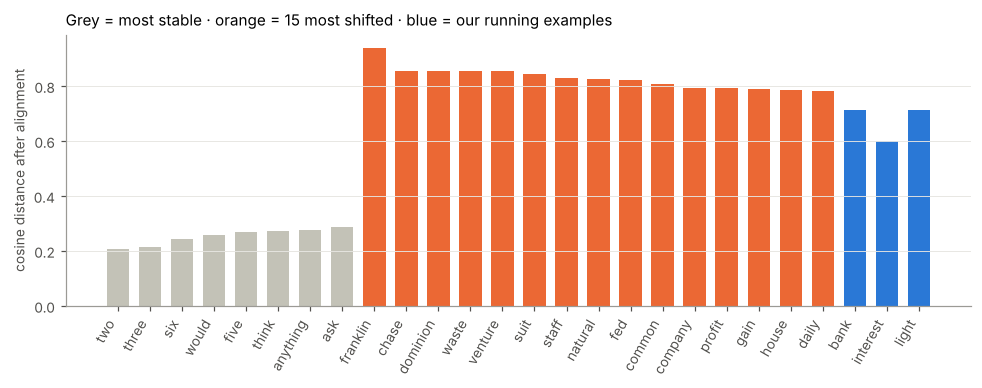

tender   R: offer, tenders, tendering, loving, tendered             G: giver, vernal, glow, wholesome, yielding
chase    R: manhattan, citibank, barclays, amp, scotia              G: vicissitudes, whales, perilous, moby, havoc
fed      R: customer, reserve, repos, bundesbank, repurchase        G: replenished, seasoned, oxen, baked, kine
suit     R: lawsuit, alleges, chancery, filed, enjoin               G: fastidious, battersby, poorly, suits, admirably
common   R: shares, unissued, berkey, voting, outstanding           G: real, disgusting, homely, morality, commercial


In [22]:
top = ranked[::-1][:15] + ["bank", "interest", "light"]
stable = ranked[:8]
words = stable + [w for w in top if w not in stable]
vals = [SHIFT[w] for w in words]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(words)), vals, width=0.7, color=["#c3c2b7"] * len(stable) + [C_G] * (len(words) - len(stable) - 3) + [C_R] * 3)
ax.set_xticks(range(len(words))); ax.set_xticklabels(words, rotation=60, ha="right")
ax.set_ylabel("cosine distance after alignment")
ax.set_title("Grey = most stable · orange = 15 most shifted · blue = our running examples", loc="left", fontsize=10)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

for w in ["tender", "chase", "fed", "suit", "common"]:
    if w in SHIFT:
        print(f"{w:8s} R: {nn(R, w, 5):55s} G: {nn(G, w, 5)}")

💬 **Discuss.**
* The **stable** words are numbers, modal verbs, *think, ask, see*: function-like words whose use did not change.
* The **shifted** ones are a list of polysemous words nobody wrote down: *tender* (a **tender offer** vs. a tender heart),
  *chase* (Chase Manhattan Bank vs. to chase), *fed* (the **Fed** vs. past of *feed*), *common* (common **stock**),
  *suit* (a law-suit vs. a suit of clothes)…
* Our running examples *bank, interest, light* shift a lot (≈ 0.6) but are not in the top: Procrustes needs many shared
  *stable* words to find the rotation, and a word whose two senses are both frequent sits in between.
* ⚠️ Not all of it is meaning: names (*franklin*) and **noise** (rare words, a single training seed) also shift.
  Try a different `seed` in §4 and see which words survive: a good habit for any embedding result.

<a id="s6"></a>
## 6. Word sense disambiguation (LO5)

**Task:** given a word **in context** and a fixed sense inventory (WordNet), choose its sense.

### 6.1 Corpus level: which sense dominates each world?
Build a vector for every WordNet sense by averaging the embeddings of its **gloss**, **examples** and **hypernyms**,
then compare it with the corpus vector of the word (McCarthy et al., 2004, *finding predominant senses*).

In [23]:
def toks(text):
    return [w.lower() for w in re.findall(r"[A-Za-z]+", text)]

def sense_signature(s, word):
    ws = toks(s.definition()) + [w for e in s.examples() for w in toks(e)] \
         + [l for h in s.hypernyms() for l in toks(" ".join(h.lemma_names()))] + toks(" ".join(s.lemma_names()))
    return [w for w in ws if w not in STOP and w != word]

def mean_vec(kv, ws):
    v = [kv[w] for w in ws if w in kv]
    return np.mean(v, 0) if v else None

def cos(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

def predominant_sense(kv, word, k=2):
    scores = []
    for s in wn.synsets(word, pos="n"):
        v = mean_vec(kv, sense_signature(s, word))
        if v is not None and word in kv:
            scores.append((cos(kv[word], v), s.name(), s.definition()[:50]))
    return sorted(scores, reverse=True)[:k]

for w in ["bank", "court", "house", "board", "interest", "mine"]:
    for name in ["reuters", "gutenberg"]:
        best = predominant_sense(W2V[name], w)[0]
        print(f"{w:9s} {name:10s} → {best[1]:38s} {best[2]}")

bank      reuters    → depository_financial_institution.n.01  a financial institution that accepts deposits and 
bank      gutenberg  → bank.n.01                              sloping land (especially the slope beside a body o
court     reuters    → court.n.08                             a tribunal that is presided over by a magistrate o
court     gutenberg  → court.n.10                             an area wholly or partly surrounded by walls or bu
house     reuters    → house.n.05                             an official assembly having legislative powers
house     gutenberg  → family.n.01                            a social unit living together
board     reuters    → board.n.01                             a committee having supervisory powers
board     gutenberg  → board.n.03                             a flat piece of material designed for a special pu
interest  reuters    → interest.n.05                          (law) a right or legal share of something; a finan
interest  gutenberg  

Without a single labelled example, the corpus vectors pick the right **dominant** sense:
*court* = tribunal vs. courtyard, *board* = committee vs. plank, *house* = legislative assembly vs. family/dwelling.
And one honest failure: in Gutenberg `mine` is a **pronoun**, which WordNet (nouns, verbs, adjectives, adverbs only) does not have.

### 6.2 Token level: disambiguating individual occurrences
We hand-labelled **24 occurrences** of `bank` (12 per corpus) with WordNet senses. The Bible ones hold a surprise:
*"they **cast up a bank** against the city"* is a **siege mound**, `bank.n.03` ("a long ridge or pile").

In [24]:
GOLD = [
{
"corpus": "reuters",
"text": "He said the bank was also proposing a one for 10 share-split which should facilitate trade in the bank's stock.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The central bank purchased bank bills outright comprising 119 mln stg in band one at 9-7/8 pct, 144 mln stg in band two at 9-13/16 pct and two mln stg in band three at 9-3/4 pct.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The company also said it has agreed in principle to acquire privately-held Pat Fashions Industries Inc for 18 mln dlrs in cash and notes, with financing to come partly from bank borrowings, subject to approval by the Pope Evans board and Pat shareholders.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "This sale will fulfill the requirements under our bank agreements to sell certain assets by June 30 and give us additional flexibility in the disposal of the remaining divisions being sold.\"",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "UAE TRADE, CURRENT ACCOUNT SURPLUSES NARROW The United Arab Emirates ( UAE ) recorded a 1986 trade surplus of 12. 2 billion dirhams, narrowing from 30. 2 billion in 1985, the central bank's latest bulletin shows.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The central bank bought bank bills outright comprising 51 mln stg in band one at 9-7/8 pct and 135 mln stg in band two at 9-13/16 pct.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The upset was compounded by news that sterling bank lending rose 2. 7 billion stg in May, above forecast, and that the Bank of England looks likely to have to sell more gilts to offset the impact on domestic money supply of its current intervention.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "Yesterday's rebound showed the market was still very respectful of the Paris accord, and the threat of central bank intervention by the G-5 nations plus Canada.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The central bank bought outright 104 mln stg in bank bills in band two at 9-13/16 pct.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The central bank's move has been combined with a steady cut in the dinar exchange rate.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "The bank official noted M-3, which includes M-1 money supply, plus savings, time deposits and deposit substitutes.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "reuters",
"text": "FED BUYS ONE BILLION DLRS OF BILLS FOR CUSTOMER The Federal Reserve is buying one billion dlrs of Treasury bills for customer account for delivery today, a spokesman for the bank said.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "gutenberg",
"text": "To give you another instance of her liberality:-- The other day, as soon as we came to town, aware that money could not be very plenty with us just now, she put bank-notes into Fanny's hands to the amount of two hundred pounds.",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "gutenberg",
"text": "19: 32 Therefore thus saith the LORD concerning the king of Assyria, He shall not come into this city, nor shoot an arrow there, nor come before it with shield, nor cast a bank against it.",
"gold": "bank.n.03"
},
{
"corpus": "gutenberg",
"text": "Getting dripping to his feet, with the water up to his knees, the worshipper of force and victory waded disconsolately to the other side and drew himself on to the bank.",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "He suddenly swung himself up the high bank on one side of the lane.",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "2: 13 He took up also the mantle of Elijah that fell from him, and went back, and stood by the bank of Jordan; 2: 14 And he took the mantle of Elijah that fell from him, and smote the waters, and said, Where is the LORD God of Elijah?",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "He was just climbing up the bank with the fat trout in his mouth.",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "Her hand he seised; and to a shady bank, Thick over-head with verdant roof imbowered, He led her nothing loth; flowers were the couch, Pansies, and violets, and asphodel, And hyacinth; Earth's freshest softest lap.",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "The wild red figure reeled an instant against the sundial; the next it had rolled down the steep bank and lay at the American's feet, faintly moving one arm.",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "The bank of England!-- Oh, DO, DO, DO!-- What's that Yarman about now?\"",
"gold": "depository_financial_institution.n.01"
},
{
"corpus": "gutenberg",
"text": "20: 15 And they came and besieged him in Abel of Bethmaachah, and they cast up a bank against the city, and it stood in the trench: and all the people that were with Joab battered the wall, to throw it down.",
"gold": "bank.n.03"
},
{
"corpus": "gutenberg",
"text": "But there was a long red stain down the bank from which the man had rolled -- that was no part of the play.",
"gold": "bank.n.01"
},
{
"corpus": "gutenberg",
"text": "47: 7 Now when I had returned, behold, at the bank of the river were very many trees on the one side and on the other.",
"gold": "bank.n.01"
}
]
print(collections.Counter((g["corpus"], g["gold"]) for g in GOLD))

Counter({('reuters', 'depository_financial_institution.n.01'): 12, ('gutenberg', 'bank.n.01'): 8, ('gutenberg', 'depository_financial_institution.n.01'): 2, ('gutenberg', 'bank.n.03'): 2})


Five methods:
1. **MFS**: WordNet's first sense (`bank.n.01`, the river side), the classic strong baseline;
2. **domain MFS**: the predominant sense **of that corpus**, from §6.1;
3. **NLTK `lesk`**: overlap between the context and the sense definitions;
4. **simplified Lesk**: overlap with definitions **+ examples**, stopwords removed (as in the slides);
5. **embedding WSD**: cosine between the averaged GloVe vector of the context (±10 words) and each sense vector.

🔮 **Predict** the ranking of the five methods on each corpus.

In [25]:
from nltk.wsd import lesk
SENSES = wn.synsets("bank", pos="n")
COARSE = {"depository_financial_institution.n.01": "FINANCE", "bank.n.05": "FINANCE", "bank.n.06": "FINANCE",
          "savings_bank.n.02": "FINANCE", "bank.n.09": "FINANCE",
          "bank.n.01": "LAND", "bank.n.03": "LAND", "bank.n.07": "LAND", "bank.n.04": "OTHER", "bank.n.10": "OTHER"}

def simplified_lesk(text):
    ctx = set(toks(text)) - STOP - {"bank"}
    def sig(s): return set(toks(s.definition() + " " + " ".join(s.examples()))) - STOP - {"bank"}
    return max(SENSES, key=lambda s: len(sig(s) & ctx)).name()   # ties → first (most frequent) sense

SENSE_VEC = {s.name(): mean_vec(GLOVE, sense_signature(s, "bank")) for s in SENSES}
def embedding_wsd(text, win=10):
    ws = toks(text); i = ws.index("bank") if "bank" in ws else 0
    ctx = [w for w in ws[max(0, i-win):i+win+1] if w not in STOP and w != "bank"]
    cv = mean_vec(GLOVE, ctx)
    return max(SENSE_VEC, key=lambda k: cos(cv, SENSE_VEC[k]))

DOMAIN_MFS = {name: predominant_sense(W2V[name], "bank", k=1)[0][1] for name in ["reuters", "gutenberg"]}
METHODS = {
    "MFS (WordNet)":   lambda g: "bank.n.01",
    "domain MFS":      lambda g: DOMAIN_MFS[g["corpus"]],
    "NLTK lesk":       lambda g: lesk(toks(g["text"]), "bank", "n").name(),
    "simplified Lesk": lambda g: simplified_lesk(g["text"]),
    "embedding (GloVe)": lambda g: embedding_wsd(g["text"]),
}
print(f"{'method':20s} {'Reuters':>9s} {'Gutenberg':>10s}   {'coarse R':>9s} {'coarse G':>9s}")
WSD_RES = {}
for mname, f in METHODS.items():
    row = []
    for corp in ["reuters", "gutenberg"]:
        d = [g for g in GOLD if g["corpus"] == corp]; pred = [f(g) for g in d]
        row.append(np.mean([p == g["gold"] for p, g in zip(pred, d)]))
        row.append(np.mean([COARSE[p] == COARSE[g["gold"]] for p, g in zip(pred, d)]))
    WSD_RES[mname] = row
    print(f"{mname:20s} {row[0]:9.2f} {row[2]:10.2f}   {row[1]:9.2f} {row[3]:9.2f}")

method                 Reuters  Gutenberg    coarse R  coarse G
MFS (WordNet)             0.00       0.67        0.00      0.83
domain MFS                1.00       0.67        1.00      0.83
NLTK lesk                 0.17       0.25        0.67      0.50


simplified Lesk           0.17       0.42        0.42      0.75
embedding (GloVe)         0.17       0.33        1.00      1.00


💬 **Discuss.**
* **MFS scores 0 % on Reuters.** WordNet's "most frequent" sense was counted on *general* text (SemCor); in finance news it is never right.
  Sense frequencies are **domain dependent**, so the *domain MFS* learned in §6.1 is a much stronger baseline.
* **Lesk** suffers from short glosses: one accidental word (*future*, *stock*) decides the sense.
* **Embeddings** get the *coarse* sense right every time (FINANCE vs. LAND) but rarely the *fine* one: the averaged context
  says "money" or "land", not "siege mound" vs. "river side".
* **Fine vs. coarse:** many errors confuse `bank.n.01` (slope by water), `n.03` (ridge) and `n.07` (slope in a road).
  Humans disagree on such fine distinctions too (≈ 75–80 % agreement), so WSD is often evaluated on **coarse** senses.
* ⚠️ 24 examples is a **toy** evaluation: one example = 8 points. Real benchmarks (SemCor, Senseval/SemEval) have thousands.

<a id="s7"></a>
## 7. Entity linking (LO5)

WSD maps a *common word* to a *concept*. **Entity linking** maps a *mention* to an *individual* in a knowledge base
(here, **Wikidata** IDs), or to **NIL** when the entity is not in the KB.
The two worlds give us real, ambiguous mentions: *Jordan* is a **country** buying wheat in Reuters and a **river** in the Bible.

A tiny KB (3 candidates for *Jordan*, 2 for *Shell*) with Wikidata IDs, short descriptions and illustrative **priors**
$P(e \mid m)$ (in real systems: how often the anchor text *Jordan* links to each Wikipedia page):

In [26]:
KB = {
 "jordan": [
  {
   "qid": "Q810",
   "label": "Jordan (country)",
   "desc": "country in Western Asia, a kingdom east of Israel with capital Amman; an Arab state in the Middle East that imports wheat and grain",
   "prior": 0.45
  },
  {
   "qid": "Q41421",
   "label": "Michael Jordan",
   "desc": "American basketball player who played for the Chicago Bulls in the NBA, scored many points and won six championships",
   "prior": 0.4
  },
  {
   "qid": "Q40059",
   "label": "Jordan River",
   "desc": "river in West Asia which flows through the Sea of Galilee to the Dead Sea; its waters, plain and valley appear in the Bible",
   "prior": 0.1
  }
 ],
 "shell": [
  {
   "qid": "Q154950",
   "label": "Shell plc",
   "desc": "British multinational oil and gas company, formerly Royal Dutch Shell, active in petroleum refining, crude oil, fuel and gasoline",
   "prior": 0.6
  },
  {
   "qid": "Q213096",
   "label": "seashell",
   "desc": "hard protective outer layer created by a marine animal such as a mollusc, snail, clam or oyster, often found on beaches by the sea",
   "prior": 0.4
  }
 ]
}
MENTIONS = [
{
"source": "Reuters",
"mention": "Jordan",
"text": "USDA said private exporters reported sales of 200,000 tonnes of wheat to Jordan for delivery during the 1987/88 marketing year.",
"gold": "Q810"
},
{
"source": "Reuters",
"mention": "Jordan",
"text": "Jordan and Co, a privately held firm based in Portland, Me., said it agreed to the merger.",
"gold": "NIL"
},
{
"source": "Gutenberg",
"mention": "Jordan",
"text": "He took up also the mantle of Elijah, and went back, and stood by the bank of Jordan, and smote the waters.",
"gold": "Q40059"
},
{
"source": "Gutenberg",
"mention": "Jordan",
"text": "And Lot lifted up his eyes, and beheld all the plain of Jordan, that it was well watered every where.",
"gold": "Q40059"
},
{
"source": "slides",
"mention": "Jordan",
"text": "Jordan scored 40 points for the Bulls last night.",
"gold": "Q41421"
},
{
"source": "Reuters",
"mention": "Shell",
"text": "The Royal Dutch/Shell Group unit agreed to pay 20 mln dlrs to settle refiner pricing issues and 160 mln dlrs to settle crude oil pricing issues.",
"gold": "Q154950"
},
{
"source": "Reuters",
"mention": "shell",
"text": "Chatsworth Enterprises Inc, a publicly held shell corporation, said it signed a letter of intent to merge.",
"gold": "NIL"
},
{
"source": "Gutenberg",
"mention": "shell",
"text": "One, two, three, came out plump and fluffy; but when the fourth shell broke, out came a little half-chick!",
"gold": "NIL"
},
{
"source": "invented",
"mention": "shell",
"text": "She picked up a beautiful pink shell from the sand on the beach near the sea.",
"gold": "Q213096"
}
]
for m in MENTIONS: print(f"[{m['source']:9s}] {m['mention']:6s} → gold {m['gold']:8s} | {m['text'][:85]}")

[Reuters  ] Jordan → gold Q810     | USDA said private exporters reported sales of 200,000 tonnes of wheat to Jordan for d
[Reuters  ] Jordan → gold NIL      | Jordan and Co, a privately held firm based in Portland, Me., said it agreed to the me
[Gutenberg] Jordan → gold Q40059   | He took up also the mantle of Elijah, and went back, and stood by the bank of Jordan,
[Gutenberg] Jordan → gold Q40059   | And Lot lifted up his eyes, and beheld all the plain of Jordan, that it was well wate
[slides   ] Jordan → gold Q41421   | Jordan scored 40 points for the Bulls last night.
[Reuters  ] Shell  → gold Q154950  | The Royal Dutch/Shell Group unit agreed to pay 20 mln dlrs to settle refiner pricing 
[Reuters  ] shell  → gold NIL      | Chatsworth Enterprises Inc, a publicly held shell corporation, said it signed a lette
[Gutenberg] shell  → gold NIL      | One, two, three, came out plump and fluffy; but when the fourth shell broke, out came
[invented ] shell  → gold Q213096  | She picked up a

Three linkers of increasing sophistication:
1. **prior only**: always the most popular entity (the EL equivalent of MFS);
2. **dense context**: cosine between the averaged GloVe vector of the sentence and of the entity description;
3. **dense + sparse NIL check**: rank with (2), but answer **NIL** when the sentence shares **no word** with *any*
   candidate's description (TF-IDF cosine = 0): no evidence → don't guess.

🔮 **Predict:** which mentions will the prior get wrong?

In [27]:
desc_tfidf = TfidfVectorizer(stop_words="english").fit([e["desc"] for c in KB.values() for e in c] + [m["text"] for m in MENTIONS])

def ctx_words(m):
    return [w for w in toks(m["text"]) if w != m["mention"].lower() and w not in STOP]

def dense_score(m, e):
    return cos(mean_vec(GLOVE, ctx_words(m)), mean_vec(GLOVE, [w for w in toks(e["desc"]) if w not in STOP]))

def sparse_score(m, e):
    text = re.sub(rf"\b{m['mention']}\b", " ", m["text"])
    return float(cosine_similarity(desc_tfidf.transform([text]), desc_tfidf.transform([e["desc"]]))[0, 0])

def link(m, method):
    cands = KB[m["mention"].lower()]
    if method == "prior":
        return max(cands, key=lambda e: e["prior"])["qid"]
    best = max(cands, key=lambda e: dense_score(m, e))
    if method == "dense+NIL" and max(sparse_score(m, e) for e in cands) == 0:
        return "NIL"
    return best["qid"]

print(f"{'gold':9s} {'prior':9s} {'dense':9s} {'dense+NIL':9s}  mention")
acc = collections.Counter()
for m in MENTIONS:
    preds = {meth: link(m, meth) for meth in ["prior", "dense", "dense+NIL"]}
    acc.update({k: v == m["gold"] for k, v in preds.items()})
    print(f"{m['gold']:9s} " + " ".join(f"{p:9s}" for p in preds.values()) + f"  {m['mention']}: {m['text'][:55]}…")
print("\naccuracy:", {k: f"{v}/{len(MENTIONS)}" for k, v in acc.items()})

gold      prior     dense     dense+NIL  mention
Q810      Q810      Q810      Q810       Jordan: USDA said private exporters reported sales of 200,000 t…
NIL       Q810      Q810      NIL        Jordan: Jordan and Co, a privately held firm based in Portland,…
Q40059    Q810      Q40059    Q40059     Jordan: He took up also the mantle of Elijah, and went back, an…
Q40059    Q810      Q40059    Q40059     Jordan: And Lot lifted up his eyes, and beheld all the plain of…
Q41421    Q810      Q41421    Q41421     Jordan: Jordan scored 40 points for the Bulls last night.…
Q154950   Q154950   Q154950   Q154950    Shell: The Royal Dutch/Shell Group unit agreed to pay 20 mln d…
NIL       Q154950   Q154950   NIL        shell: Chatsworth Enterprises Inc, a publicly held shell corpo…
NIL       Q154950   Q213096   NIL        shell: One, two, three, came out plump and fluffy; but when th…
Q213096   Q154950   Q213096   Q213096    shell: She picked up a beautiful pink shell from the sand on t…

accura

💬 **Discuss.**
* The **prior** sends the Bible's *Jordan* to the **country**: a prior estimated on Wikipedia is wrong for the Bible.
  Same lesson as MFS in §6: **frequencies are domain dependent**.
* **Dense context** fixes the ranking but **never says NIL**: averaged vectors are never exactly orthogonal, so every
  sentence is "somewhat similar" to every description (*Jordan and Co*, a firm in Portland, gets linked to the country).
* The **sparse** check is crude but honest: zero shared words → no evidence. Note that we chose this rule *looking at
  these 9 examples*: a real system would **learn** the NIL threshold on held-out data.
* *"the fourth **shell** broke, out came a little half-chick"*: an **eggshell**. It is neither Shell plc nor a seashell → NIL.
  The KB is always **incomplete**: NIL detection is part of the task.

### 7.1 🌐 Live: candidate generation from Wikidata
Real linkers do not have a 5-entry KB: they **generate candidates** from millions of entities. The Wikidata search API
returns candidates (with their descriptions) for any mention. *(Needs internet; it works on Colab.)*

In [28]:
import urllib.request, urllib.parse
def wikidata_candidates(mention, k=6, lang="en"):
    url = "https://www.wikidata.org/w/api.php?" + urllib.parse.urlencode(
        dict(action="wbsearchentities", search=mention, language=lang, format="json", limit=k, type="item"))
    req = urllib.request.Request(url, headers={"User-Agent": "SemShift-tutorial/1.0 (NLP course, ISEL)"})
    with urllib.request.urlopen(req, timeout=10) as r:
        return [(c["id"], c.get("label", ""), c.get("description", "")) for c in json.load(r)["search"]]

try:
    for mention in ["Jordan", "Shell", "Delta", "Apple"]:
        print(f"\n{mention}:")
        for qid, label, desc in wikidata_candidates(mention):
            print(f"   {qid:10s} {label:28s} {desc}")
except Exception as e:
    print("Wikidata not reachable from here (offline?):", type(e).__name__)

(Run this cell on Colab: it queries the live Wikidata API.)


✏️ **Try it:** Reuters also says *"oil find in Alaska's Colville **Delta** area"* and *"merger of **Delta** Airlines Inc"*.
Add a `delta` entry to `KB` with the candidates returned above and run the three linkers on both sentences.

| | **WSD** | **Entity linking** |
|---|---|---|
| targets | common words (*bank, court*) | named mentions (*Jordan, Shell*) |
| inventory | WordNet senses (concepts), ≈ 5–20 per word | KB entities (individuals), millions |
| unknown target | rare | frequent → **NIL** |
| frequency baseline | MFS | prior $P(e\mid m)$ |
| shared lesson today | **both baselines are domain dependent** | |

<a id="s8"></a>
## 8. Limitations of static embeddings (LO6)

### 8.1 One vector per word type (polysemy)
GloVe has **one** vector for `bank`, mixing all senses, weighted by frequency in Wikipedia + news.

In [29]:
print("bank          →", nn(GLOVE, "bank", 8))
print("bank + river  →", ", ".join(w for w, _ in GLOVE.most_similar(positive=["bank", "river"], topn=8)))
print("bank - money + river →", ", ".join(w for w, _ in GLOVE.most_similar(positive=["bank", "river"], negative=["money"], topn=8)))
print()
for a, b in [("hot", "cold"), ("good", "bad"), ("buy", "sell"), ("cup", "mug")]:
    print(f"cos({a}, {b}) = {GLOVE.similarity(a, b):.2f}")
print("\nOut-of-vocabulary: 'jaguar' in Gutenberg?", "jaguar" in W2V["gutenberg"], "| 'governess' in Reuters?", "governess" in W2V["reuters"])

bank          → banks, banking, credit, investment, financial, securities, lending, funds
bank + river  → banks, shore, central, along, flows, rivers, west, crossing
bank - money + river → danube, estuary, rivers, rhine, tigris, meuse, elbe, tagus

cos(hot, cold) = 0.73
cos(good, bad) = 0.77
cos(buy, sell) = 0.94
cos(cup, mug) = 0.18

Out-of-vocabulary: 'jaguar' in Gutenberg? False | 'governess' in Reuters? False


* the vector is dominated by the **most frequent sense**: you must *push* it towards *river* to find the other one;
* **antonyms** (*hot/cold*, *buy/sell*) are closer than true near-synonyms (*cup/mug*): they share contexts;
* **OOV**: a word never seen has no vector (fastText's character n-grams help);
* the same vector is used in **every sentence**. **Contextual embeddings** (ELMo, BERT) give one vector **per token**: later in the course.

### 8.2 Bias: embeddings learn the stereotypes of their texts
Project occupation words on the **gender direction** $\vec{he} - \vec{she}$ (normalised).
🔮 **Predict:** which occupations will be most "female" in 19th-century novels? And in GloVe?

reuters    count('he') =  5,208   count('she') =    163
gutenberg  count('he') = 25,734   count('she') =  9,040


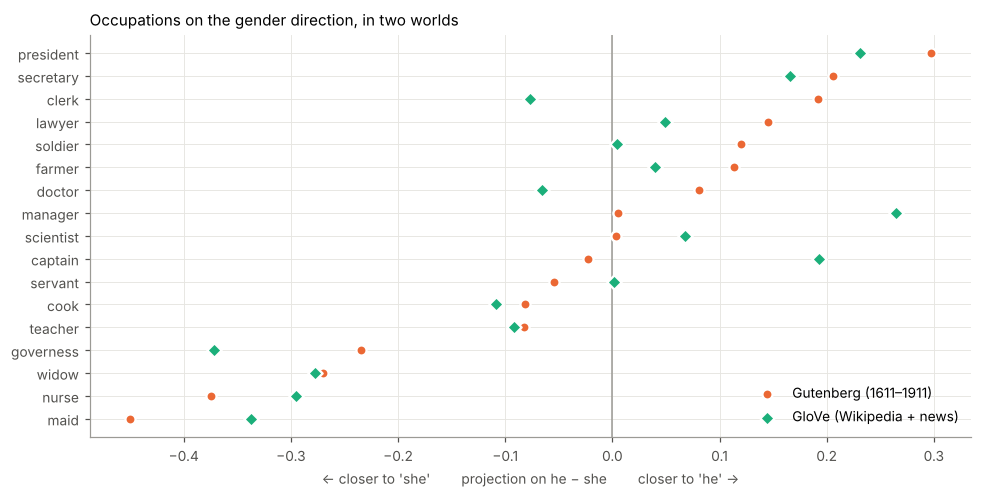

In [30]:
OCC = ["maid", "nurse", "governess", "cook", "servant", "teacher", "widow", "doctor", "lawyer",
       "captain", "soldier", "farmer", "clerk", "secretary", "president", "engineer", "scientist", "manager"]
def gender_proj(kv, words):
    d = kv["he"] - kv["she"]; d /= np.linalg.norm(d)
    return {w: float(kv[w] @ d / np.linalg.norm(kv[w])) for w in words if w in kv}

for name, kv in [("reuters", W2V["reuters"]), ("gutenberg", W2V["gutenberg"])]:
    print(f"{name:10s} count('he') = {kv.get_vecattr('he','count'):6,d}   count('she') = {kv.get_vecattr('she','count'):6,d}")

PG, PW = gender_proj(W2V["gutenberg"], OCC), gender_proj(GLOVE, OCC)
words = sorted(PG, key=PG.get)
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(words))
ax.axvline(0, color="#9b9a95", linewidth=1)
ax.scatter([PG[w] for w in words], y, s=44, color=C_G, edgecolor="white", linewidth=1.5, label="Gutenberg (1611–1911)", zorder=3)
ax.scatter([PW.get(w, np.nan) for w in words], y, s=44, color=C_W, marker="D", edgecolor="white", linewidth=1.5, label="GloVe (Wikipedia + news)", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(words)
ax.set_xlabel("← closer to 'she'        projection on he − she        closer to 'he' →")
ax.legend(loc="lower right", frameon=False)
ax.set_title("Occupations on the gender direction, in two worlds", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

💬 **Discuss.**
* In the novels *maid, nurse, widow, governess, cook* lean to *she*; *president, clerk, lawyer, secretary* lean to *he*.
  In 19th-century Britain a *secretary* was a man's post (and in news it is *Secretary of State*: polysemy again).
* In Reuters 1987 `she` is **≈ 30× rarer** than `he` (163 vs. 5,208): women are simply **absent** from financial news, a
  *representational* harm before any geometry.
* GloVe reproduces modern stereotypes (*nurse, governess, teacher* vs. *manager, captain, president*), and some words **moved**:
  *clerk* is on the *he* side in the novels and on the *she* side in modern text, as clerical work changed hands.
* An embedding is a **mirror of its corpus**:
  used in CV screening, search or translation it can turn those stereotypes into **allocational** harms.
* "Debiasing" by removing the gender direction **hides** the bias rather than removing it (Gonen & Goldberg, 2019).

<a id="s9"></a>
## 9. 🇵🇹 Bonus: *rede*, *pena*, *real*: Machado de Assis vs. *Folha de S. Paulo*

NLTK ships two Portuguese corpora: the **complete works of Machado de Assis** (1839–1908, ≈ 2.5 M words) and
**Mac-Morpho**, news from *Folha de S. Paulo* (1994, ≈ 1 M words). Same recipe, ≈ 2 minutes.

🔮 **Prevê:** what do *rede*, *pena*, *real* and *capital* mean in each world?

In [31]:
from nltk.corpus import machado, mac_morpho
def clean_pt(sents):
    out = [[w.lower() for w in s if re.fullmatch(r"[^\W\d_][\w'-]*", w)] for s in sents]
    return [s for s in out if len(s) > 2]

t = time.time()
PT = {}
for name, corp in [("Machado de Assis", machado), ("Folha 1994", mac_morpho)]:
    PT[name] = Word2Vec(clean_pt(corp.sents()), vector_size=100, window=5, sg=1, negative=5,
                        min_count=5, epochs=10, workers=2, seed=42).wv
print(f"trained in {time.time()-t:.0f} s")
for w in ["rede", "pena", "real", "capital", "juros", "sala"]:
    print(f"\n{w}")
    for name, kv in PT.items():
        print(f"   {name:17s} {nn(kv, w, 6)}")

trained in 110 s

rede
   Machado de Assis  esteira, reclinado, chaminé, borda, poltrona, deitada
   Folha 1994        internet, computadores, bbs, conexão, redes, novell

pena
   Machado de Assis  descrevo, inserir, bagagem, pego, cronista, bastará
   Folha 1994        réu, sentença, perpétua, licença, prisão, insistência

real
   Machado de Assis  apetecida, nutro, contigüidade, diplomática, vassalo, intrigante
   Folha 1994        fundão, urv, julho, cruzado, dólar, paridade

capital
   Machado de Assis  território, goiás, lavoura, bahia, comuna, metrópole
   Folha 1994        transferiu, brahma, china, sede, ásia, infra-estrutura

juros
   Machado de Assis  ordenados, setecentos, ganhos, emprestados, vencimentos, dinheiros
   Folha 1994        taxas, taxa, tr, cdbs, ipmf, variaram

sala
   Machado de Assis  saleta, varanda, alcova, soleira, contígua, chácara
   Folha 1994        lapa, praia, festa, danceteria, praça, janela


*rede* = hammock (*esteira, poltrona, reclinado*) → **computer network** (*internet, computadores*);
*pena* has no clear neighbours in Machado (it mixes pity, the writer's pen and *valer a pena*: one vector for three senses
is a good vector for none) → a prison **sentence** in Folha (*réu, sentença, prisão*); *real* = royal/real → the **currency** (*URV, julho, cruzado, paridade*: the
*Plano Real* replaced the *cruzeiro real* in July 1994!). Polysemy, homonymy and even **semantic change in time** in one cell.

<a id="s10"></a>
## 10. Wrap-up

| LO | What you saw today |
|---|---|
| LO1 | WordNet: 10 noun senses of *bank*; synonyms, hypernym paths, hyponyms, meronyms, antonyms; homonymy is language specific |
| LO2 | The neighbours of *bank* in two corpora already reveal two meanings |
| LO3 | Sparse TF-IDF (books) and PPMI (words, > 98 % zeros); dense word2vec (100 d) and GloVe |
| LO4 | Cosine everywhere: books, words, sense vectors, entity descriptions, aligned spaces |
| LO5 | WSD (MFS, Lesk, embeddings, *domain MFS*) vs. entity linking (prior, context, **NIL**) |
| LO6 | SGNS training in ~1 min; one vector per word, antonyms, OOV, **bias as a mirror of the corpus** |

**The one-sentence takeaway:** *a word vector is a summary of a corpus*. Change the corpus and you change
the meaning, the dominant sense, the priors and the stereotypes.

### ✏️ Challenges (pick one)
1. **Window size.** Retrain with `window=2` and `window=10`. Do neighbours become more *similar* or more *related*?
2. **Robustness.** Retrain both models with 3 different seeds. Which shifted words in §5 survive all runs?
3. **Better WSD.** Use *domain-specific* sense vectors (the corpus's own word2vec instead of GloVe) in `embedding_wsd`. Better?
4. **Add a world.** NLTK has `inaugural` (US presidential speeches 1789–2021). Compare *union*, *state*, *liberty*.
5. **Diachronic bias.** Split `inaugural` into before/after 1900 and repeat §8.2.

### 📚 References
* Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft), ch. 6 (vector semantics) and Appendix G (WSD).
* Mikolov et al. (2013) *Distributed representations of words and phrases and their compositionality*. NeurIPS.
* Pennington, Socher & Manning (2014) *GloVe: Global vectors for word representation*. EMNLP.
* Levy, Goldberg & Dagan (2015) *Improving distributional similarity with lessons learned from word embeddings*. TACL.
* McCarthy, Koeling, Weeds & Carroll (2004) *Finding predominant word senses in untagged text*. ACL.
* Hamilton, Leskovec & Jurafsky (2016) *Diachronic word embeddings reveal statistical laws of semantic change*. ACL.
* Bolukbasi et al. (2016) *Man is to computer programmer as woman is to homemaker?* NeurIPS; Gonen & Goldberg (2019) *Lipstick on a pig*. NAACL.
* Milne & Witten (2008) *Learning to link with Wikipedia*. CIKM.

In [32]:
print(f"Total runtime: {(time.time()-T0)/60:.1f} min")

Total runtime: 4.2 min
